Ukuran data: (2060, 562)
Melatih model Regresi Logistik Standar...
Akurasi Model: 96.12%

Laporan Klasifikasi:
              precision    recall  f1-score   support

   Berbaring       0.99      1.00      1.00       122
     Berdiri       0.94      0.90      0.92       106
    Berjalan       0.96      0.99      0.98       111
       Duduk       0.91      0.94      0.93       113
 Naik_Tangga       0.96      0.96      0.96        81
Turun_Tangga       1.00      0.98      0.99        85

    accuracy                           0.96       618
   macro avg       0.96      0.96      0.96       618
weighted avg       0.96      0.96      0.96       618



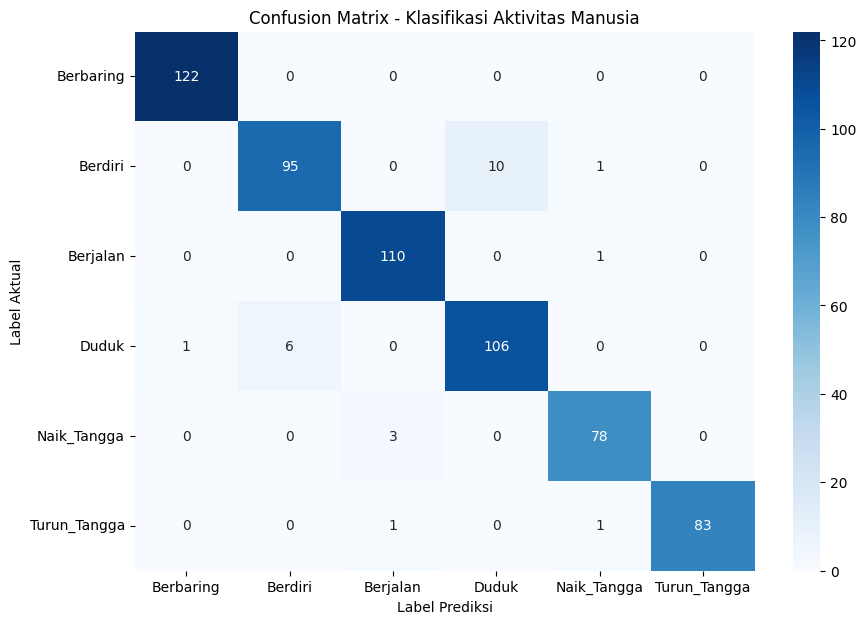

In [1]:
  import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

# 1. Muat Dataset
# Pastikan nama file sesuai dengan yang diunggah
df = pd.read_csv('HAR_Modified_Final.csv')
print("Ukuran data:", df.shape)

# 2. Persiapan Data & Encoding Target
feature_cols = df.columns[:-1]
target_col = 'Activity'

# Mengubah label teks bahasa Indonesia menjadi angka (0, 1, 2, dst)
le = LabelEncoder()
df['Activity_Encoded'] = le.fit_transform(df[target_col])

# 3. Pembagian Data (Train/Test Split)
# Menggunakan StratifiedShuffleSplit agar proporsi aktivitas seimbang
strat_shuf_split = StratifiedShuffleSplit(n_splits=1, test_size=0.3, random_state=42)
train_idx, test_idx = next(strat_shuf_split.split(df[feature_cols], df['Activity_Encoded']))

X_train = df.loc[train_idx, feature_cols]
y_train = df.loc[train_idx, 'Activity_Encoded']
X_test  = df.loc[test_idx, feature_cols]
y_test  = df.loc[test_idx, 'Activity_Encoded']

# 4. Pelatihan Model Regresi Logistik
print("Melatih model Regresi Logistik Standar...")
lr_model = LogisticRegression(solver='liblinear', multi_class='ovr').fit(X_train, y_train)

# 5. Prediksi dan Evaluasi
y_pred = lr_model.predict(X_test)
akurasi = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {akurasi * 100:.2f}%\n")

print("Laporan Klasifikasi:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# 6. Visualisasi Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title('Confusion Matrix - Klasifikasi Aktivitas Manusia')
plt.ylabel('Label Aktual')
plt.xlabel('Label Prediksi')
plt.show()